# DCF Valuation of Apple Inc. (AAPL)

A discounted cash flow (DCF) model built in Python, using financial data from Yahoo Finance.

**Result (as of November 2026):** base-case value of about **\$131 per share** vs. a market price of about **\$343**.
A sensitivity analysis shows the market price is only justified with a WACC near 6% and terminal growth of 3–3.5%.

**Steps:**
1. Data: income statement, cash flow statement, balance sheet
2. Free cash flow to the firm (FCFF)
3. 5-year forecast
4. Beta (own regression) and WACC
5. Terminal value
6. Enterprise value → value per share
7. Sensitivity analysis

## Step 1: Setup and data
Imports the Python libraries and downloads Apple's annual financial statements (income statement,
cash flow statement, balance sheet) and company information from Yahoo Finance via the `yfinance` library.
The tables are transposed so that each row is a fiscal year, oldest first.

In [45]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from scipy import stats

ticker = yf.Ticker("AAPL")
income_t = ticker.income_stmt.T.sort_index()
cf_t = ticker.cashflow.T.sort_index()
bal_t = ticker.balance_sheet.T.sort_index()
info = ticker.info

## Step 2: Free cash flow (FCFF)
Free cash flow to the firm is the cash the business generates after taxes and the investments needed
to keep it running, i.e. the cash available to all investors (shareholders and lenders).

FCFF = EBIT × (1 − tax rate) + D&A − CapEx − change in net working capital

Note on signs: in Yahoo's data, CapEx is stored as a negative number and the change in working capital
is stored from the cash point of view, so both are **added** in the code.

In [46]:
print(f"Average effective tax rate: {tax_rate:.1%}")

fcff_table = pd.DataFrame({
    "EBIT": ebit,
    "Taxes on EBIT": -ebit * tax_rate,
    "D&A": da,
    "CapEx": capex,
    "Change NWC": change_nwc,
    "FCFF": fcff,
}).dropna() / 1e9

fcff_table["FCF margin %"] = fcff / revenue * 100
fcff_table["Net margin %"] = income_t["Net Income"] / revenue * 100
display(fcff_table.round(1))

Average effective tax rate: 17.9%


,EBIT,Taxes on EBIT,D&A,CapEx,Change NWC,FCFF,FCF margin %,Net margin %
2023-09-30,114.3,-20.4,11.5,-11.0,-6.6,87.9,22.9,25.3
2024-09-30,123.2,-22.0,11.4,-9.4,3.7,106.9,27.3,24.0
2025-09-30,133.0,-23.8,11.7,-12.7,-25.0,83.3,20.0,26.9
2026-09-30,158.1,-28.2,13.4,-9.0,-14.9,119.4,24.9,27.6


FCF is more volatile than net income (FCF margin 20–27% vs. net margin 24–28%), mainly because of
working capital timing, e.g. in FY2025 cash tied up in working capital pushed the FCF margin down to 20%.
This is why the forecast uses average or median ratios instead of a single year.

## Step 3: 5-year forecast
Revenue is forecast first; all other items are expressed as a percentage of revenue, based on their
historical values. This keeps every assumption visible and easy to change.

### 3a: History

In [47]:
ratios = pd.DataFrame({
    "EBIT margin": ebit / revenue,
    "D&A %": da / revenue,
    "CapEx %": capex / revenue,
    "NWC change %": change_nwc / revenue,
})

growth = revenue.pct_change() * 100
history = (ratios * 100).assign(**{"Revenue growth %": growth}).dropna()
display(history.round(1))
display((ratios.mean() * 100).round(1).rename("Average %"))

,EBIT margin,D&A %,CapEx %,NWC change %,Revenue growth %
2024-09-30,31.5,2.9,-2.4,0.9,2.0
2025-09-30,32.0,2.8,-3.1,-6.0,6.4
2026-09-30,33.0,2.8,-1.9,-3.1,15.1


EBIT margin     31.6
D&A %            2.9
CapEx %         -2.6
NWC change %    -2.5
Name: Average %, dtype: float64

### 3b: Assumptions
- **Revenue growth** 8% → 7% → 5% → 4% → 3%: the 15% growth in FY2026 is treated as a one-off;
  growth fades towards the long-run rate.
- **EBIT margin** 32.5%: between the 4-year average (31.6%) and the latest year (33%), reflecting the rising trend.
- **NWC change** = median of historical values, to reduce the impact of extreme years (conservative).
- **D&A and CapEx** = historical averages (both stable).

In [48]:
assumptions = {
    "growth": [0.08, 0.07, 0.05, 0.04, 0.03],   # 15% in 2026 seen as one-off; fade to 3%
    "ebit_margin": 0.325,                        # between average (31.6%) and latest (33%)
    "da_pct": ratios["D&A %"].mean(),
    "capex_pct": ratios["CapEx %"].mean(),
    "nwc_pct": ratios["NWC change %"].median(),  # median to reduce extremes
    "tax_rate": tax_rate,
}

### 3b: Forecast

In [49]:
rows = []
rev = revenue.iloc[-1]
for year, g_year in enumerate(assumptions["growth"], start=1):
    rev = rev * (1 + g_year)
    ebit_f = rev * assumptions["ebit_margin"]
    fcff_f = (ebit_f * (1 - assumptions["tax_rate"])
              + rev * assumptions["da_pct"]
              + rev * assumptions["capex_pct"]
              + rev * assumptions["nwc_pct"])
    rows.append({"year": year, "revenue": rev, "ebit": ebit_f, "fcff": fcff_f})

forecast = pd.DataFrame(rows).set_index("year")

forecast_table = forecast[["revenue", "ebit", "fcff"]] / 1e9
forecast_table.columns = ["Revenue (bn)", "EBIT (bn)", "FCFF (bn)"]
forecast_table["FCF margin %"] = forecast["fcff"] / forecast["revenue"] * 100
display(forecast_table.round(1))

,Revenue (bn),EBIT (bn),FCFF (bn),FCF margin %
year,,,,
1,517.1,168.1,127.3,24.6
2,553.3,179.8,136.2,24.6
3,581.0,188.8,143.0,24.6
4,604.2,196.4,148.8,24.6
5,622.4,202.3,153.2,24.6


Revenue grows from about 479 bn (FY2026) to about 622 bn in year 5. The forecast FCF margin (≈24.6%)
is close to recent history (24.9% in FY2026), so the forecast is consistent with Apple's past performance.

## Step 4: Calculating beta and WACC
### 4a: Beta (own regression)

In [50]:
prices = yf.download(["AAPL", "^GSPC"], period="5y", interval="1mo", auto_adjust=True, progress = False)["Close"]
prices = prices.iloc[:-1]                      # drop unfinished month
returns = prices.pct_change().dropna()
returns.columns = ["apple", "market"]

x = returns["market"]
y = returns["apple"]
x_mean, y_mean = x.mean(), y.mean()
beta_manual = ((x - x_mean) * (y - y_mean)).sum() / ((x - x_mean)**2).sum()
alpha_manual = y_mean - beta_manual * x_mean

result = stats.linregress(x, y)
print(f"Own beta: {beta_manual:.3f}  (scipy: {result.slope:.3f}, SE {result.stderr:.3f})")

Own beta: 1.085  (scipy: 1.085, SE 0.153)


### 4b: WACC

In [51]:
tnx = yf.Ticker("^TNX").history(period="5d")
risk_free = tnx["Close"].iloc[-1] / 100
equity_premium = 0.05
cost_equity = risk_free + beta_manual * equity_premium

E = info["marketCap"]
D = bal_t["Total Debt"].iloc[-1]
interest = income_t["Interest Expense"].dropna() if "Interest Expense" in income_t else pd.Series(dtype=float)
if len(interest) > 0:
    cost_debt = abs(interest.iloc[-1]) / D
else:
    cost_debt = risk_free + 0.01

wacc = (E/(E+D)) * cost_equity + (D/(E+D)) * cost_debt * (1 - tax_rate)

print(f"Risk-free: {risk_free:.2%}, cost of equity: {cost_equity:.2%}, cost of debt: {cost_debt:.2%}")
print(f"Weights: equity {E/(E+D):.1%}, debt {D/(E+D):.1%}")
print(f"WACC: {wacc:.2%}")

Risk-free: 4.92%, cost of equity: 10.34%, cost of debt: 4.91%
Weights: equity 98.4%, debt 1.6%
WACC: 10.24%


## Step 5: Terminal value
Cash flows after year 5 are valued with the Gordon growth formula, assuming 3% growth forever.

In [52]:
g = 0.03
N = len(forecast)

fcff_last = forecast["fcff"].iloc[-1]
tv = fcff_last * (1 + g) / (wacc - g)
pv_tv = tv / (1 + wacc) ** N

print(f"FCFF year 5: {fcff_last/1e9:.1f} bn")
print(f"Terminal value (year 5): {tv/1e9:.0f} bn")
print(f"PV of terminal value (today): {pv_tv/1e9:.0f} bn")


FCFF year 5: 153.2 bn
Terminal value (year 5): 2178 bn
PV of terminal value (today): 1338 bn


The terminal value makes up about 72% of the enterprise value. The DCF is most sensitive to the terminal
growth rate and the WACC, because the terminal value depends on the gap between them: raising g by one
percentage point (e.g. 3% → 4%) increases the PV of the terminal value by roughly 15–17%.

## Step 6: From cash flows to value per share
### 6a: Present value of the forecast cash flows
Money received in the future is worth less today, so each year's FCFF is multiplied by a discount
factor, 1 / (1 + WACC)^t. The further away the year, the smaller the factor.

In [53]:
years = np.arange(1, N + 1)
forecast["discount_factor"] = 1 / (1 + wacc) ** years
forecast["pv_fcff"] = forecast["fcff"] * forecast["discount_factor"]

summary = pd.DataFrame({
    "FCFF (bn)": forecast["fcff"] / 1e9,
    "Discount factor": forecast["discount_factor"],
    "PV of FCFF (bn)": forecast["pv_fcff"] / 1e9,
})
display(summary.round({"FCFF (bn)": 1, "Discount factor": 3, "PV of FCFF (bn)": 1}))

,FCFF (bn),Discount factor,PV of FCFF (bn)
year,,,
1,127.3,0.907,115.5
2,136.2,0.823,112.1
3,143.0,0.746,106.8
4,148.8,0.677,100.7
5,153.2,0.614,94.1


Although FCFF grows from 127 bn to 153 bn over the five years, its present value falls from 116 bn to 94 bn,
because discounting outweighs growth: at a WACC of about 10%, \$1 received in year 5 is worth only about
\$0.61 today. Together, the five forecast years are worth about 529 bn today.

### 6b: Enterprise value
The enterprise value (EV) is the value of the whole business, belonging to both shareholders and lenders.
It is the sum of the present values of the forecast cash flows (years 1–5) and the terminal value.

In [54]:
pv_forecast = forecast["pv_fcff"].sum()
ev = pv_forecast + pv_tv

print(f"PV of FCFF years 1–5: {pv_forecast/1e9:,.0f} bn")
print(f"PV of terminal value: {pv_tv/1e9:,.0f} bn")
print(f"Enterprise value:     {ev/1e9:,.0f} bn")
print(f"Terminal value share: {pv_tv/ev:.0%}")

PV of FCFF years 1–5: 529 bn
PV of terminal value: 1,338 bn
Enterprise value:     1,867 bn
Terminal value share: 72%


### Step 6c: Equity value and value per share
FCFF belongs to all investors, so the enterprise value includes the lenders' share. To get the value
for shareholders, debt is subtracted, and cash and long-term investments (which belong to shareholders
on top of the business) are added. Dividing by the number of shares gives the value per share,
which can be compared with the market price.

In [55]:
cash = bal_t["Cash And Cash Equivalents"].iloc[-1]
investments = bal_t["Investments And Advances"].iloc[-1]
shares = info["sharesOutstanding"]
price = info["currentPrice"]

equity_value = ev - D + cash + investments
value_per_share = equity_value / shares

print(f"Enterprise value:  {ev/1e9:,.0f} bn")
print(f"− Debt:            {D/1e9:,.0f} bn")
print(f"+ Cash:            {cash/1e9:,.0f} bn")
print(f"+ Investments:       {investments/1e9:,.0f} bn")
print(f"= Equity value:    {equity_value/1e9:,.0f} bn")
print(f"Shares:            {shares/1e9:.2f} bn")
print(f"\nDCF value per share: ${value_per_share:.2f}")
print(f"Market price:        ${price:.2f}")
print(f"Difference:          {value_per_share/price - 1:.0%}")

Enterprise value:  1,867 bn
− Debt:            80 bn
+ Cash:            36 bn
+ Investments:       80 bn
= Equity value:    1,903 bn
Shares:            14.53 bn

DCF value per share: $130.97
Market price:        $349.18
Difference:          -62%


At a 10.3% WACC and 3% terminal growth, Apple is worth about USD 131 per share.
The market price of USD 342 implies either a WACC of around 6% or long-term growth of around 8%,
assumptions that are optimistic but explain why investors pay a premium for Apple.

## Step 7: Sensitivity analysis

### 7a: The valuation as a function
The whole valuation (Steps 5–6) is packed into one function, `dcf_value`, so it can be recalculated
quickly for any WACC and terminal growth rate. As a check, it reproduces the base case from Step 6.

In [56]:
from matplotlib.colors import TwoSlopeNorm
from matplotlib.patches import Rectangle

def dcf_value(fcff, wacc, g, debt, cash, investments, shares):
    years = np.arange(1, len(fcff) + 1)
    pv_forecast = (fcff / (1 + wacc) ** years).sum()        # PV of forecast years
    tv = fcff[-1] * (1 + g) / (wacc - g)                    # terminal value (Gordon growth)
    pv_tv = tv / (1 + wacc) ** years[-1]                    # discounted to today
    ev = pv_forecast + pv_tv                                # enterprise value
    equity_value = ev - debt + cash + investments           # value for shareholders
    return equity_value / shares                            # value per share

fcff_values = forecast["fcff"].values
investments = bal_t["Investments And Advances"].iloc[-1]

base = dcf_value(fcff_values, wacc, g, D, cash, investments, shares)
print(f"Base case: ${base:.2f}  (WACC {wacc:.2%}, g {g:.1%})  vs. market price ${price:.2f}")

Base case: $130.97  (WACC 10.24%, g 3.0%)  vs. market price $349.18


The function reproduces the base case of USD 131 per share, about 62% below the market price of USD 343.
Since the valuation depends heavily on the WACC and the terminal growth rate, the next step tests
how the value changes across a range of both.

### 7b: The sensitivity table
Value per share for every combination of WACC (6–12%) and terminal growth g (1–4%), calculated with `dcf_value`.

In [57]:
wacc_range = np.arange(0.06, 0.1201, 0.01)     # 6% to 12%
g_range = np.arange(0.01, 0.0401, 0.005)       # 1.0% to 4.0% (always below WACC)

table = pd.DataFrame(index=[f"{w:.0%}" for w in wacc_range],
                     columns=[f"{x:.1%}" for x in g_range],
                     dtype=float)

for w in wacc_range:
    for x in g_range:
        table.loc[f"{w:.0%}", f"{x:.1%}"] = dcf_value(fcff_values, w, x, D, cash, investments, shares)

display(table.round(0).astype(int))

,1.0%,1.5%,2.0%,2.5%,3.0%,3.5%,4.0%
6%,203,221,244,274,314,370,453
7%,169,181,196,213,236,265,303
8%,145,153,163,175,189,206,228
9%,127,133,140,148,158,169,183
10%,113,117,123,129,135,143,153
11%,101,105,109,114,119,125,131
12%,92,95,98,102,106,110,115


Only the combination of a 6% WACC with 3.0–3.5% terminal growth comes close to the market price of USD 343.
Per step, the WACC has the larger effect (about USD 23 per row vs. USD 8 per column around the base case),
and the effect of g increases sharply when the WACC is low. The heatmap below shows these patterns visually.

### 7c: The heatmap
The sensitivity table as a heatmap. Colours are centred on the market price (USD 343):
red cells are below it, green cells above it. The black box marks the cell closest to the base case.

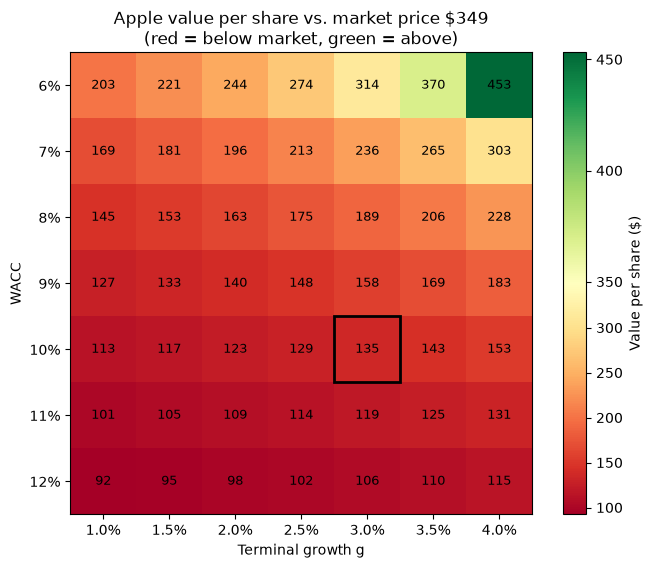

In [58]:
norm = TwoSlopeNorm(vmin=min(table.values.min(), price * 0.9),
                    vcenter=price,
                    vmax=max(table.values.max(), price * 1.1))

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(table.values, cmap="RdYlGn", norm=norm)

ax.set_xticks(range(len(g_range)))
ax.set_xticklabels(table.columns)
ax.set_yticks(range(len(wacc_range)))
ax.set_yticklabels(table.index)
ax.set_xlabel("Terminal growth g")
ax.set_ylabel("WACC")
ax.set_title(f"Apple value per share vs. market price ${price:.0f}\n(red = below market, green = above)")

for i in range(len(wacc_range)):
    for j in range(len(g_range)):
        ax.text(j, i, f"{table.values[i, j]:.0f}", ha="center", va="center", fontsize=9)

# box around the cell closest to the base case
row = np.argmin(np.abs(wacc_range - wacc))
col = np.argmin(np.abs(g_range - g))
ax.add_patch(Rectangle((col - 0.5, row - 0.5), 1, 1, fill=False, edgecolor="black", linewidth=2))

plt.colorbar(im, label="Value per share ($)")
plt.savefig("sensitivity.png", dpi=150, bbox_inches="tight")
plt.show()

## Conclusion
Across WACC 6–12% and terminal growth 1–4%, the DCF values Apple between USD 92 and USD 453 per share.
The base case (WACC ≈ 10.3%, g = 3%) gives about USD 131. The market price of USD 343 is only reached with a WACC
near 6% and terminal growth of 3–3.5%, which implies a very low equity risk premium given the ~5% risk-free rate.
More plausibly, the market expects substantially higher growth than this forecast assumes.
The valuation is most sensitive to the WACC, and the effect of terminal growth increases sharply as the WACC falls.